In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt

# Five-minute bars are assumed to be labeled by their opening timestamp.
root = Path.cwd()
if not (root / "data/5mNQData.csv").exists():
    root = root.parent
rawData = pd.read_csv(root / "data/5mNQData.csv")
rawData["timestamp_utc"] = pd.to_datetime(rawData["timestamp_utc"], utc=True).dt.tz_convert("America/New_York")
rawData = rawData.rename(columns={"timestamp_utc":"Date", "open":"Open", "high":"High", "low":"Low", "close":"Close", "volume":"Volume", "risk_free_rate_annual":"RiskFreeRate"})
NQ = rawData.set_index("Date").sort_index().between_time("09:30", "15:55").copy()
if NQ.index.has_duplicates:
    raise ValueError("Duplicate timestamps: resolve the source data before backtesting")
invalid = (NQ.High < NQ[["Open", "Close", "Low"]].max(axis=1)) | (NQ.Low > NQ[["Open", "Close", "High"]].min(axis=1)) | NQ[["Open", "High", "Low", "Close", "RiskFreeRate"]].isna().any(axis=1)
if invalid.any():
    raise ValueError(f"{invalid.sum()} invalid bars: inspect source data")
# Retain volatile days: range alone is not evidence of corruption.
# ATR is unused by this strategy, so no warm-up day is discarded.
print(f"Data: {NQ.index.min()} to {NQ.index.max()}")
NQ


Data: 2021-08-19 09:30:00-04:00 to 2026-08-18 15:55:00-04:00


,Open,High,Low,Close,Volume,RiskFreeRate
Date,,,,,,
2021-08-19 09:30:00-04:00,18149.75,18200.50,18139.00,18190.25,23037,0.0007
2021-08-19 09:35:00-04:00,18190.25,18211.00,18157.50,18165.50,18662,0.0007
2021-08-19 09:40:00-04:00,18165.00,18186.00,18148.50,18175.75,14554,0.0007
2021-08-19 09:45:00-04:00,18176.00,18208.75,18150.75,18171.00,17364,0.0007
2021-08-19 09:50:00-04:00,18171.25,18202.75,18169.00,18196.50,11882,0.0007
...,...,...,...,...,...,...
2026-08-18 15:35:00-04:00,29591.75,29600.25,29584.25,29594.00,2267,0.0386
2026-08-18 15:40:00-04:00,29593.75,29605.00,29582.75,29600.25,2946,0.0386
2026-08-18 15:45:00-04:00,29600.25,29607.00,29588.00,29597.75,3488,0.0386


In [2]:
"""#5M ORB
balance = 25000
TP_ratio = 2
trade_open = False
contract_size = 2
wins_5m = 0
loss_5m = 0

#use to track trades and results
trades_list_5m = []
balance_history_5m = []

close_gap = 1

ORB_high = None
ORB_low = None


- set the orb high and low
- iterate each day until 11 where everything will reset
- look for a break of orb h/l
for i, row in NQ.iterrows():
    if(i.hour == 13 and i.minute == 30):
        ORB_high = row.High
        ORB_low = row.Low
    #check if a trade can be opened
    if (i.hour < 15) and (not trade_open) and (ORB_high is not None) and (ORB_low is not None):
        if row.Close > ORB_high + close_gap:
            #breakout of high
            entry_price = row.Close
            entry_time = i.time()
            entry_index = i
            trade_open = True
            position = "long"
            SL = ORB_high
            TP = entry_price + ((entry_price - SL) * TP_ratio)
        elif row.Close < ORB_low + close_gap:
            #breakout of low
            entry_price = row.Close
            entry_time = i.time()
            entry_index = i
            trade_open = True
            position = "short"
            SL = ORB_low
            TP = entry_price - ((SL - entry_price) * TP_ratio)
    #when a trade is open
    if trade_open and i != entry_index:
        #check if SL or TP is hit
        if(i.hour == 19 and i.minute == 55):
            #If it hits 4:00, all trades close
            if position == "long":
                if row.High >= TP:
                    trade_open = False
                    exit_price = TP
                    wins_5m += 1
                elif row.Low <= SL:
                    trade_open = False
                    exit_price = SL
                    loss_5m += 1
                elif row.Close >= entry_price:
                    trade_open = False
                    exit_price = row.Close
                    wins_5m += 1
                elif row.Close < entry_price:
                    trade_open = False
                    exit_price = row.Close
                    loss_5m += 1
            elif position == "short":
                if row.Low <= TP:
                    trade_open = False
                    exit_price = TP
                    wins_5m += 1
                elif row.High >= SL:
                    trade_open = False
                    exit_price = SL
                    loss_5m += 1
                elif row.Close <= entry_price:
                    trade_open = False
                    exit_price = row.Close
                    wins_5m += 1
                elif row.Close > entry_price:
                    trade_open = False
                    exit_price = row.Close
                    loss_5m += 1  
        elif position == "long":
            if row.High >= TP:
                trade_open = False
                exit_price = TP
                wins_5m += 1
            elif row.Low <= SL:
                trade_open = False
                exit_price = SL
                loss_5m += 1
        elif position == "short":
            if row.Low <= TP:
                trade_open = False
                exit_price = TP
                wins_5m += 1
            elif row.High >= SL:
                trade_open = False
                exit_price = SL
                loss_5m += 1

        #calculate PnL and balance
        if not trade_open:
            exit_time = i.time()
            if position == "long":
                pnl = (exit_price - entry_price) * 2 * contract_size
            elif position == "short":
                pnl = (entry_price - exit_price) * 2 * contract_size
            balance += pnl

            #Store trades taken in a new list
            trade = [entry_time, entry_price, exit_time, exit_price, position, pnl, balance]
            trades_list_5m.append(trade)
    #Track balance
    #Balance is out of the loop so it has a value corresponding to every "Date" in the dataframe
    balance_history_5m.append(balance) 
    
    """

'#5M ORB\nbalance = 25000\nTP_ratio = 2\ntrade_open = False\ncontract_size = 2\nwins_5m = 0\nloss_5m = 0\n\n#use to track trades and results\ntrades_list_5m = []\nbalance_history_5m = []\n\nclose_gap = 1\n\nORB_high = None\nORB_low = None\n\n\n- set the orb high and low\n- iterate each day until 11 where everything will reset\n- look for a break of orb h/l\nfor i, row in NQ.iterrows():\n    if(i.hour == 13 and i.minute == 30):\n        ORB_high = row.High\n        ORB_low = row.Low\n    #check if a trade can be opened\n    if (i.hour < 15) and (not trade_open) and (ORB_high is not None) and (ORB_low is not None):\n        if row.Close > ORB_high + close_gap:\n            #breakout of high\n            entry_price = row.Close\n            entry_time = i.time()\n            entry_index = i\n            trade_open = True\n            position = "long"\n            SL = ORB_high\n            TP = entry_price + ((entry_price - SL) * TP_ratio)\n        elif row.Close < ORB_low + close_gap:\n

In [3]:
from datetime import time
import runpy

# Read this exact source file on every run; avoid cached notebook imports.
ENGINE_PATH = root / "backtestprogram" / "orb_engine.py"
run_orb = runpy.run_path(str(ENGINE_PATH))["run_orb"]
print("Engine:", ENGINE_PATH.resolve())

SIGNAL_START = time(9, 45)
SIGNAL_END = time(13, 30)  # Preserves your edited signal cutoff.
# Signals fill at the next bar open; no new entry on the session-final bar.
print("Signal window:", SIGNAL_START, "to", SIGNAL_END)

INITIAL_BALANCE = 25000
POINT_VALUE = 2  # Dollars per point per contract; verify against the traded instrument.
CONTRACTS = 1
COMMISSION = 1  # Round trip per contract, in dollars.
SLIPPAGE_POINTS = 0  # Set an instrument-appropriate assumption for sensitivity analysis.
# Existing strategy filters retained: exclude June and ranges >= 150 points.
# Session exits use the last observed bar, including shortened sessions.
trades_15m, equity_history, balance_history = run_orb(
    NQ, initial_balance=INITIAL_BALANCE, point_value=POINT_VALUE,
    contracts=CONTRACTS, tp_ratio=1, commission=COMMISSION,
    slippage_points=SLIPPAGE_POINTS,
    signal_start=SIGNAL_START, signal_end=SIGNAL_END,
)


Engine: /Users/teddieshi/Documents/vscode/backtest/algotrading/backtestprogram/orb_engine.py
Signal window: 09:45:00 to 13:30:00


In [4]:
wins_15m = int((trades_15m.PnL > 0).sum())
loss_15m = int((trades_15m.PnL < 0).sum())
count = len(trades_15m)
win_rate_15m = wins_15m / count * 100 if count else np.nan
loss_rate_15m = loss_15m / count * 100 if count else np.nan
avg_win = trades_15m.loc[trades_15m.PnL > 0, "PnL"].mean()
avg_loss = trades_15m.loc[trades_15m.PnL < 0, "PnL"].mean()
Percent_increase_15m = (balance_history.Balance.iloc[-1] / INITIAL_BALANCE - 1) * 100
expectancy = trades_15m.PnL.mean()
gross_losses = -trades_15m.loc[trades_15m.PnL < 0, "PnL"].sum()
profit_factor = trades_15m.loc[trades_15m.PnL > 0, "PnL"].sum() / gross_losses if gross_losses else np.nan
worstDD = balance_history.Drawdown.min()
equity_drawdown = equity_history / equity_history.cummax().clip(lower=INITIAL_BALANCE) - 1
std = balance_history.Excess_Return.std()
sharpe = balance_history.Excess_Return.mean() / std * np.sqrt(252) if std > 0 else np.nan
print("Trades:", count)
print("Net win rate (%):", win_rate_15m)
print("Total return (%):", Percent_increase_15m)
print("Average win ($):", avg_win, "Average loss ($):", avg_loss)
print("Expectancy ($/trade):", expectancy)
print("Expectancy (R/trade):", trades_15m.R.mean())
print("Profit factor:", profit_factor)
print("Worst daily drawdown (%):", worstDD * 100)
print("Worst bar-close equity drawdown (%):", equity_drawdown.min() * 100)
print("Daily Sharpe:", sharpe)
print("Ambiguous exits (stop first):", trades_15m.Ambiguous.sum())


Trades: 2016
Net win rate (%): 55.307539682539684
Total return (%): 138.564
Average win ($): 166.30762331838565 Average loss ($): -167.54666666666665
Expectancy ($/trade): 17.183035714285715
Expectancy (R/trade): 0.07297953898744804
Profit factor: 1.229727041222346
Worst daily drawdown (%): -7.710439591129981
Worst bar-close equity drawdown (%): -9.780616962259392
Daily Sharpe: 1.3349700103356517
Ambiguous exits (stop first): 0


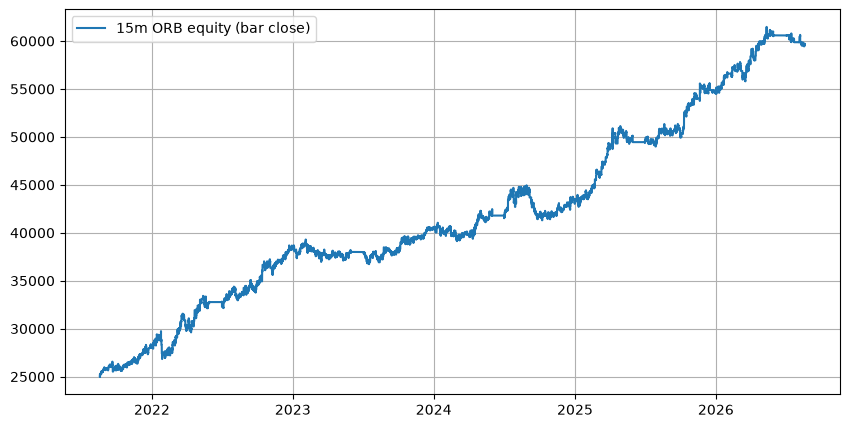

In [5]:
plt.figure(figsize=(10,5))
plt.plot(equity_history.index, equity_history, label="15m ORB equity (bar close)")
plt.ticklabel_format(style="plain", axis="y")
plt.legend()
plt.grid(visible=True)
